# Anamorphosis: one detector pixel per voxel

In `slicersim`, the detector turns the noise-free cube into signal and variance with
`Detector.estimate_pixel_signal`. Its `npix_per_voxel` parameter is the number of detector
pixels over which the flux of one **voxel** (one spaxel × one wavelength bin) is spread. Every
one of these pixels adds its own read noise, dark current, ROIC glow and thermal dark. So this
parameter sets the detector noise of every simulated spectrum.

The Lazuli image slicer is **anamorphic**: a spaxel is imaged onto 1 × 2 detector pixels. Up
to version 1.4, `slicersim` used `npix_per_spaxel = 2` (the anamorphosis factor). From version
1.5, a slicer uses **`npix_per_voxel = 1`**. This notebook shows why 1 is the right value.

![Image slicer with anamorphosis: from the sky to the detector pixels](../gallery/anamorphosis_schematic.png)

In short: the 2 pixels of the anamorphosis lie **along the dispersion**. There, `slicersim`'s
wavelength bins already *are* detector pixels, and the 2-pixel image of the slit is the line
spread function (LSF), which spreads light over neighbouring bins. Counting the 2 pixels again in
the detector step counts the anamorphosis twice. See also {doc}`../anamorphosis`.

We show it three ways:

1. from the instrument description: one wavelength bin is one pixel, and one spaxel is one pixel
   along the slice;
2. from a single voxel, whose variance can be written down by hand;
3. from the optical design: an emission line projected onto the detector pixels with the spot
   data, with a Monte Carlo on these pixels.

We then look at what the change does to signal-to-noise ratios and exposure times.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas
import matplotlib.pyplot as plt

import slicersim
from slicersim import iotools
from slicersim.detector import Detector
from slicersim.mapper import SlicerMapper

slicersim.__version__

'1.5.0'

## 1. What a voxel is on the detector

### Along the dispersion, one wavelength bin is one pixel

The Lazuli wavelength grid is built from the dispersion law (the detector pixel offset as a
function of wavelength), with one bin per detector pixel. The anamorphosis is in the
`dispersion_resolution`: a resolution element (the LSF) spans 2.3 bins, i.e. 2.3 pixels.

In [2]:
target = slicersim.LazuliTarget(np.linspace(3_000, 20_000, 5_000), np.full(5_000, 1e-18))
spectro = target.simulation.spectrograph

config = iotools.get_config(instrument="lazuli_cbe.toml")["spectrograph"]
law = iotools.read_ecsv(iotools.expand_path(config["dispersion_law"]), colnames=["wavelength", "offset"])
scale = config["dispersion_scale"] * config["dispersion_resolution"] / 2  # as in build_lbda_from_config
offset = np.interp(np.log([4_000, 17_000]),
                   np.log(law["wavelength"].to("AA").value), law["offset"].value) * scale  # [pixel]

print(f"4000-17000 Å spans {offset[1] - offset[0]:.0f} detector pixels")
print(f"wavelength bins in the cube: {len(spectro.lbda)}")
print(f"pixels per resolution element (LSF): {spectro.dispersion_resolution}")

4000-17000 Å spans 524 detector pixels
wavelength bins in the cube: 525
pixels per resolution element (LSF): 2.3


### Along the slice, one spaxel is one pixel

The spot data of the optical design (`SlicerMapper`) gives the length of a slice on the
detector. A slice holds 116 spaxels of 40 mas:

In [3]:
mapper = SlicerMapper.from_data(pandas.read_csv(iotools.expand_path("mapping_spotdata.csv"), sep=" "))
nslices, nspaxels = spectro.spx_shape

for sliceid in [1, 30, 58]:
    edge_1, edge_2 = (np.ravel(mapper.slice_pos_wave_to_xy(sliceid=sliceid, fieldpos=pos_, lbda=12_000))
                      for pos_ in [-1, 1])
    print(f"slice {sliceid:2d}: {np.hypot(*(edge_2 - edge_1)):.0f} detector pixels for {nspaxels} spaxels")

slice  1: 108 detector pixels for 116 spaxels
slice 30: 105 detector pixels for 116 spaxels
slice 58: 105 detector pixels for 116 spaxels


One voxel (1 spaxel × 1 wavelength bin) is therefore **one detector pixel**. A monochromatic
image of a spaxel covers 2 pixels along the dispersion, but the next wavelength bin is shifted by
only 1 pixel: neighbouring bins share pixels. Over $K$ wavelength bins, a spaxel trace covers
$K + 1$ pixels, not $2K$ (panel 5 of the figure above).

## 2. A single voxel, by hand

The cleanest test: a flat-spectrum point source whose light falls in a **single spaxel**, with no
LSF, no sky, no thermal emission and no dark current. Each wavelength bin of the extracted
spectrum is then exactly one voxel, and its variance can be written down by hand.

- flat spectrum, $F_\lambda = 10^{-18}$ erg/s/cm²/Å;
- read-out MACC(16, 1, 0), one ramp, gain = 1 (ADU = e⁻).

In [4]:
lbda_in = np.linspace(3_000, 20_000, 5_000)
target = slicersim.LazuliTarget(lbda_in, np.full(lbda_in.shape, 1e-18))
target.change_detector(nmd=(16, 1, 0), nramps=1)

sim = target.simulation
det, spectro = sim.detector, sim.spectrograph
lbda = spectro.lbda

SWITCH_OFF = ["background", "thermal", "dark", "thermal_dark", "roic_glow"]  # keep: pointsource and ron

**No PSF:** we replace the spectrograph PSF with a "delta" PSF. It is used both to put the source
in the cube and as the weights of the (optimal) extraction, so each wavelength bin of the
extracted spectrum is exactly that voxel.

In [5]:
position = sim.scene.pointsource_position
(x, y), _ = spectro.get_spaxel_centroids()
iy, ix = np.unravel_index(np.argmin(np.hypot(x - position[0], y - position[1])), spectro.spx_shape)

def get_delta_psf(*args, **kwargs):
    # all the light in spaxel (iy, ix), at all wavelengths
    psf = np.zeros((len(lbda), *spectro.spx_shape))
    psf[:, iy, ix] = 1
    return psf

spectro.get_spatial_psf = get_delta_psf  # instance-level override, removed below
print(f"the source is in spaxel (row, column) = ({iy}, {ix})")

the source is in spaxel (row, column) = (28, 57)


For one detector pixel receiving $f$ e⁻/s, an up-the-ramp read-out MACC(n, m, d) gives a signal
$S = f\, t_\mathrm{int}$ and a variance (Rauscher et al. 2007, as in `Detector.estimate_variance`):

$$\mathrm{Var}_\mathrm{pixel} = \sigma^2_\mathrm{RON,eff} + \alpha\,f, \qquad
\sigma^2_\mathrm{RON,eff} = \frac{12\,(n-1)}{m\,n\,(n+1)}\,\sigma^2_\mathrm{RON}, \qquad
\alpha = \frac{6\,(n^2+1)}{5\,n\,(n+1)}\,(n-1)\,t_\mathrm{group} - \frac{2\,(m^2-1)\,(n-1)}{m\,n\,(n+1)}\,t_\mathrm{frame}$$

The flux in the voxel is the input spectrum times the instrument response,
$f = F_\lambda \times$ `flambda2photon` $\times$ QE.

- If a voxel is **one** pixel: $\mathrm{Var} = \sigma^2_\mathrm{RON,eff} + \alpha f$.
- If a voxel is **two** pixels, each receiving $f/2$: $\mathrm{Var} = 2\,\sigma^2_\mathrm{RON,eff} + \alpha f$.

The photon noise is the same in both cases. Only the read noise (and any other per-pixel term)
doubles.

In [6]:
n, m, d = det.nmd
t_frame = det.meta["tframe"]
t_group = t_frame * (m + d)
t_int = (n - 1) * t_group

sigma2 = det.get_effective_ron(as_variance=True)  # [e-²] per pixel
alpha = 6 * (n**2 + 1) / (5 * n * (n + 1)) * (n - 1) * t_group - 2 * (m**2 - 1) * (n - 1) / (m * n * (n + 1)) * t_frame

_, flux_lambda = sim.scene.get_element_spectrum("pointsource", lbda=lbda)  # input spectrum on the cube grid
f = flux_lambda * spectro.flambda2photon * det.get_qe(lbda=lbda)           # [e-/s] in the voxel

expected_signal = f * t_int
expected_variance = {1: sigma2 + alpha * f,      # one pixel per voxel
                     2: 2 * sigma2 + alpha * f}  # two pixels per voxel
print(f"t_int = {t_int:.2f} s | sigma2_RON,eff = {sigma2:.2f} e-² | alpha = {alpha:.2f} s")

t_int = 42.45 s | sigma2_RON,eff = 95.29 e-² | alpha = 48.13 s


And `slicersim`'s spectrum (noise-free, without the LSF):

In [7]:
lbda, signal, variance = sim.get_spectrum(switch_off=SWITCH_OFF, apply_lsf=False)

print(f"signal   / expected              : {np.nanmedian(signal / expected_signal):.4f}")
print(f"variance / expected (1 px/voxel) : {np.nanmedian(variance / expected_variance[1]):.4f}")
print(f"variance / expected (2 px/voxel) : {np.nanmedian(variance / expected_variance[2]):.4f}")

signal   / expected              : 1.0000
variance / expected (1 px/voxel) : 1.0000
variance / expected (2 px/voxel) : 0.5130


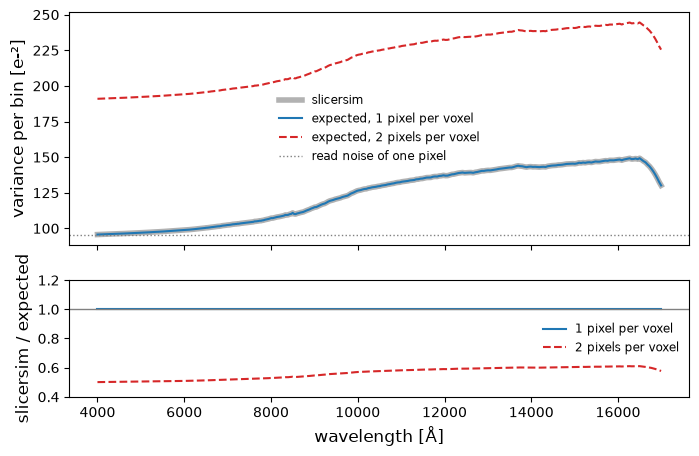

In [8]:
fig, (ax, axr) = plt.subplots(2, 1, figsize=(8, 5), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
ax.plot(lbda, variance, color="k", lw=4, alpha=0.3, label="slicersim")
ax.plot(lbda, expected_variance[1], color="C0", label="expected, 1 pixel per voxel")
ax.plot(lbda, expected_variance[2], color="C3", ls="--", label="expected, 2 pixels per voxel")
ax.axhline(sigma2, color="0.5", lw=1, ls=":", label="read noise of one pixel")
ax.set_ylabel("variance per bin [e-²]", fontsize="large")
ax.legend(frameon=False, fontsize="small")

axr.plot(lbda, variance / expected_variance[1], color="C0", label="1 pixel per voxel")
axr.plot(lbda, variance / expected_variance[2], color="C3", ls="--", label="2 pixels per voxel")
axr.axhline(1, color="0.5", lw=1)
axr.set_ylim(0.4, 1.2)
axr.set_xlabel("wavelength [Å]", fontsize="large")
axr.set_ylabel("slicersim / expected", fontsize="large")
axr.legend(frameon=False, fontsize="small")

The signal is exact, and the variance is exactly that of **one pixel per voxel**.

With the LSF switched on, the result is the same: the LSF only moves flux between neighbouring
wavelength bins, i.e. between neighbouring pixels of the same spaxel trace. It does not change the
number of pixels read. The expected variance simply uses the smoothed flux:

In [9]:
f_lsf = spectro.apply_line_spread_function(flux_lambda) * spectro.flambda2photon * det.get_qe(lbda=lbda)
lbda, signal_lsf, variance_lsf = sim.get_spectrum(switch_off=SWITCH_OFF, apply_lsf=True)
del spectro.get_spatial_psf  # back to the normal PSF

print(f"variance / expected (1 px/voxel) : {np.nanmedian(variance_lsf / (sigma2 + alpha * f_lsf)):.4f}")
print(f"variance / expected (2 px/voxel) : {np.nanmedian(variance_lsf / (2 * sigma2 + alpha * f_lsf)):.4f}")

variance / expected (1 px/voxel) : 1.0000
variance / expected (2 px/voxel) : 0.5129


## 3. From the optical design: an emission line on the detector pixels

The test above checks that `slicersim` does what the formula says. This one checks the formula
against the optical design, without assuming any number of pixels per voxel.

- a point source with a single emission line at 12 000 Å (Gaussian, σ = 50 Å, total flux
  $2\times10^{-15}$ erg/s/cm²), no continuum;
- no sky, no thermal emission, no dark current, no ROIC glow: the only noises are the read noise
  and the photon noise of the line;
- read-out MACC(16, 1, 0), one ramp, gain = 1.

*The line is wider than a wavelength bin (about 43 Å at 1.2 µm): `slicersim` samples the input
spectrum at the bin centres, so a narrower line would lose most of its flux.*

In [10]:
lbda_in = np.linspace(3_000, 20_000, 20_000)
line_flux, line_center, line_sigma = 2e-15, 12_000, 50  # erg/s/cm², Å, Å
flux_in = line_flux * np.exp(-0.5 * ((lbda_in - line_center) / line_sigma)**2) / (np.sqrt(2 * np.pi) * line_sigma)

target = slicersim.LazuliTarget(lbda_in, flux_in + 1e-30)
target.change_detector(nmd=(16, 1, 0), nramps=1)

sim = target.simulation
det, spectro = sim.detector, sim.spectrograph
lbda = spectro.lbda
sim.update(detector__dark=0, detector__roic_glow=0, optics__emissivity=0)  # read noise only

scene = sim.get_projected_scene(in_photons=True, switch_off=["background", "thermal"])  # [ph/s/voxel]

# the detector step, with 1 (slicersim >= 1.5) or 2 (slicersim <= 1.4) pixels per voxel
signal, variance = {}, {}
for npix in [1, 2]:
    signal[npix], variance[npix] = det.estimate_pixel_signal(scene, lbda=lbda, npix_per_voxel=npix)  # [ADU], [ADU²]

print("the signal does not depend on npix_per_voxel:", np.allclose(signal[1], signal[2]))

the signal does not depend on npix_per_voxel: True


The footprint of the line is the set of voxels receiving at least 0.1% of the peak signal. We
project it onto the detector with the spot data, and count the detector pixels it covers:

line footprint: 320 voxels -> 383 detector pixels (1.20 pixels per voxel)


Text(0, 0.5, 'y [pixel]')

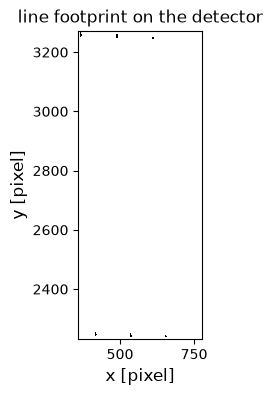

In [11]:
footprint = signal[1] > 1e-3 * signal[1].max()
n_voxels = footprint.sum()

image = mapper.project_lazulicube(footprint.astype(float), "narrow", lbda)
n_pixels = np.count_nonzero(image)
print(f"line footprint: {n_voxels} voxels -> {n_pixels} detector pixels ({n_pixels / n_voxels:.2f} pixels per voxel)")

fig, ax = plt.subplots(figsize=(4, 4))
ys, xs = np.nonzero(image)
ax.imshow(image, origin="lower", cmap="Greys", interpolation="nearest")
ax.set_xlim(xs.min() - 5, xs.max() + 5)
ax.set_ylim(ys.min() - 5, ys.max() + 5)
ax.set_title("line footprint on the detector")
ax.set_xlabel("x [pixel]", fontsize="large")
ax.set_ylabel("y [pixel]", fontsize="large")

The line covers about 1.2 detector pixels per voxel, not 2. The extra 0.2 comes from the
dispersion: around 1.2 µm, one wavelength bin of the `slicersim` dispersion law is about
1.2 pixels of the spot-data dispersion.

Summing the line over $N$ pixels, the signal-to-noise ratio is

$$\mathrm{SNR} = \frac{S}{\sqrt{N\,\sigma^2_\mathrm{RON,eff} + \alpha\, f_\mathrm{tot}}}$$

The photon noise does not depend on how the flux is split among pixels; the read noise is paid
once per pixel. Finally, a Monte Carlo that uses no voxel-to-pixel assumption: we put the line on
the detector pixels given by the spot data, draw the noise of each pixel, and sum them.

In [12]:
sigma2 = det.get_effective_ron(as_variance=True)
n, m, d = det.nmd
t_int = det.electronpers_to_adu()  # [s], gain = 1
t_frame = det.meta["tframe"]
t_group = t_frame * (m + d)
alpha = 6 * (n**2 + 1) / (5 * n * (n + 1)) * (n - 1) * t_group - 2 * (m**2 - 1) * (n - 1) / (m * n * (n + 1)) * t_frame

total_signal = signal[1][footprint].sum()  # [e-]
f_tot = total_signal / t_int               # [e-/s]

# Monte Carlo on the detector pixels of the spot data
line_image = mapper.project_lazulicube(np.where(footprint, signal[1], 0), "narrow", lbda)
line_image *= f_tot / line_image.sum()     # [e-/s/pixel], same total flux
f_pix = line_image[line_image > 0]

rng = np.random.default_rng(42)
draws = f_pix * t_int + rng.normal(0, np.sqrt(sigma2 + alpha * f_pix), size=(5_000, f_pix.size))
measured = draws.sum(axis=1)

rows = [("formula, 1 pixel per voxel", n_voxels, total_signal / np.sqrt(n_voxels * sigma2 + alpha * f_tot)),
        ("formula, spot-data pixels", n_pixels, total_signal / np.sqrt(n_pixels * sigma2 + alpha * f_tot)),
        ("formula, 2 pixels per voxel", 2 * n_voxels, total_signal / np.sqrt(2 * n_voxels * sigma2 + alpha * f_tot)),
        ("Monte Carlo on the spot-data pixels", f_pix.size, measured.mean() / measured.std()),
        ("slicersim, npix_per_voxel=1 (>= 1.5)", None, total_signal / np.sqrt(variance[1][footprint].sum())),
        ("slicersim, npix_per_voxel=2 (<= 1.4)", None, total_signal / np.sqrt(variance[2][footprint].sum())),
        ]
pandas.DataFrame(rows, columns=["case", "N pixels", "SNR"]).set_index("case").round(2)

,N pixels,SNR
case,,
"formula, 1 pixel per voxel",320.0,8.41
"formula, spot-data pixels",383.0,7.72
"formula, 2 pixels per voxel",640.0,6.03
Monte Carlo on the spot-data pixels,383.0,7.79
"slicersim, npix_per_voxel=1 (>= 1.5)",NaN,8.41
"slicersim, npix_per_voxel=2 (<= 1.4)",NaN,6.03


The Monte Carlo on the real detector pixels agrees with one pixel per voxel, up to the 1.2
factor of the dispersion above. Two pixels per voxel underestimates the signal-to-noise ratio.

## 4. Impact on signal-to-noise and exposure time

To see what the change does, we emulate the former behaviour by forcing 2 pixels per voxel in the
detector step of a target (instance-level override, removed afterwards).

In [13]:
def set_two_pixels_per_voxel(detector):
    # emulates slicersim <= 1.4: the detector step always spreads a voxel over 2 pixels
    detector.estimate_pixel_signal = lambda flux_, npix_per_voxel=1, **kwargs: Detector.estimate_pixel_signal(
        detector, flux_, npix_per_voxel=2, **kwargs)

def unset_two_pixels_per_voxel(detector):
    del detector.estimate_pixel_signal

### Signal-to-noise of a flat spectrum

Default `LazuliTarget`, flat $F_\lambda$, optimal extraction, noise-free spectrum:

In [14]:
lbda_in = np.linspace(3_000, 20_000, 5_000)
lbda_test = [5_000, 10_000, 15_000]

rows = []
for flux_ in [3e-18, 3e-17]:
    target = slicersim.LazuliTarget(lbda_in, np.full(lbda_in.shape, flux_))
    lbda, sig, var = target.get_spectrum(incl_error=False)
    snr_1 = sig / np.sqrt(var)

    set_two_pixels_per_voxel(target.simulation.detector)
    lbda, sig, var = target.get_spectrum(incl_error=False)
    snr_2 = sig / np.sqrt(var)
    unset_two_pixels_per_voxel(target.simulation.detector)

    index = [np.argmin(np.abs(lbda - l_)) for l_ in lbda_test]
    for l_, i_ in zip(lbda_test, index):
        rows.append({"F_lambda": flux_, "lbda": l_, "SNR (2 px/voxel)": snr_2[i_], "SNR (1 px/voxel)": snr_1[i_]})

snr_impact = pandas.DataFrame(rows).set_index(["F_lambda", "lbda"])
snr_impact["gain [%]"] = 100 * (snr_impact["SNR (1 px/voxel)"] / snr_impact["SNR (2 px/voxel)"] - 1)
snr_impact.round(2)

SNR (2 px/voxel)  SNR (1 px/voxel)  gain [%]
F_lambda     lbda                                               
3.000000e-18 5000               2.72              3.43     26.24
             10000             19.91             21.42      7.55
             15000             24.69             26.77      8.41
3.000000e-17 5000              15.06             16.05      6.58
             10000             73.78             74.83      1.43
             15000             93.07             94.61      1.65

### Exposure time of a Type Ia supernova

Exposure time to reach SNR = 20 (`setup_to_snr`), for a SN Ia at peak:

In [15]:
rows = []
for redshift in [0.5, 1.0, 1.5]:
    snia = slicersim.LazuliSupernova(redshift=redshift)
    snia.setup_to_snr(20)
    exptime_1 = snia.get_exposure_time()

    set_two_pixels_per_voxel(snia.simulation.detector)
    snia.setup_to_snr(20)
    exptime_2 = snia.get_exposure_time()
    unset_two_pixels_per_voxel(snia.simulation.detector)

    rows.append({"redshift": redshift, "exptime (2 px/voxel) [s]": exptime_2, "exptime (1 px/voxel) [s]": exptime_1})

exptime_impact = pandas.DataFrame(rows).set_index("redshift")
exptime_impact["ratio"] = exptime_impact["exptime (2 px/voxel) [s]"] / exptime_impact["exptime (1 px/voxel) [s]"]
exptime_impact.round(2)

,exptime (2 px/voxel) [s],exptime (1 px/voxel) [s],ratio
redshift,,,
0.5,882.96,792.40,1.11
1.0,3667.68,2897.92,1.27
1.5,17387.52,11591.68,1.50


- **Photon-limited cases** (bright sources, the red end) change by a few percent at most.
- **Detector-limited cases** (faint, distant sources, the blue end where the read noise
  dominates) are the most affected: two pixels per voxel underestimated the signal-to-noise
  ratio by up to about 25%, and overestimated exposure times by up to about 1.5×.

## Conclusion

- One voxel (1 spaxel × 1 wavelength bin) is **one detector pixel** in a slicer. The
  anamorphosis puts 2 pixels along the dispersion, where they are already the wavelength sampling
  and the LSF (2.3 pixels per resolution element).
- A single voxel's variance in `slicersim` is exactly $\sigma^2_\mathrm{RON,eff} + \alpha f$,
  the variance of one pixel.
- The optical design (spot data) puts a line on about 1.2 pixels per voxel. A Monte Carlo on
  these pixels gives the one-pixel-per-voxel signal-to-noise ratio, not the two-pixel one.

Hence `slicersim` 1.5 uses `npix_per_voxel=1` in the detector step of slicer spectrographs.